<a href="https://colab.research.google.com/github/vzavala/DoE/blob/main/Python/ch6_gibbs_kriging.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Setup.** Run this cell first: it locates the data files this notebook reads. On Google
Colab it downloads them (the `Data/` and `Support/` folders) from the course's GitHub
repository; on your computer, run the notebook from the folder that contains `Data/`.

In [1]:
import os
import sys
path = ''
if 'google.colab' in sys.modules and not os.path.isdir('Data'):
    if not os.path.isdir('doe'):
        os.system('git clone -q --depth 1 --filter=blob:none --sparse '
                  'https://github.com/vzavala/DoE.git doe')
        os.system('git -C doe sparse-checkout set Python/Data Python/Support')
    path = 'doe/Python/'

Kriging (Gaussian process) model for the Gibbs reactor (Victor Z and Ugochukwu Ikegwu, UW-Madison, 2024).

| Slides | Python | Meaning |
|---|---|---|
| $X=(P,T)$, $Y=C$ | `X`, `y` | inputs (pressure, temperature) and conversion |
| $k(x,x',\gamma)$, $\hat{\gamma}$, $\sigma^2$ | `kernel`, `gp.kernel_` | Matern kernel plus noise term, and their MLE values |
| $m(x)$, $\sigma(x)$ | `m_x`, `sigma_x` | predictive mean and SD |
| $\epsilon_\omega$ | `eps_gp`, `eps_lin` | residuals of kriging and linear models |

**Note:** This notebook reproduces Example 6.24 (Section 6.6) of *Statistics for Chemical Engineers*: a Gaussian process (kriging) model of the Gibbs reactor, compared with linear regression.

**The concept.** Kriging (a GP) treats the unknown function as random with covariance given by a kernel. Here it is the Matern kernel ($\nu=3/2$) plus measurement noise,

$$k(x,x',\ell)=\left(1+\frac{\sqrt{3}\,r}{\ell}\right)\exp\!\left(-\frac{\sqrt{3}\,r}{\ell}\right),\qquad r=\lVert x-x'\rVert,\qquad \mathbf{C}=\mathbf{K}+\sigma^2I.$$

Conditioning on the data gives the prediction and its uncertainty,

$$m(x)=\mathbf{k}(x)^T\mathbf{C}^{-1}\mathbf{y},\qquad \sigma^2(x)=c(x)-\mathbf{k}(x)^T\mathbf{C}^{-1}\mathbf{k}(x).$$

A linear model has one slope everywhere; kriging adapts to the data and also reports where it is uncertain.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel
from sklearn.linear_model import LinearRegression

data = np.vstack((np.loadtxt(path+'Data/gibbs_hightemp_class.dat'),
                  np.loadtxt(path+'Data/gibbs_lowtemp_class.dat')))
S = len(data)
np.random.seed(1)
X = np.column_stack((data[:, 1], data[:, 0])) + np.random.rand(S, 2) * 0.1   # (P, T)
y = data[:, 2] + np.random.rand(S) * 0.1                                     # C

Fit $\hat{\gamma}$ by maximizing $\log f(\mathbf{y}|\gamma)$, then predict with
$m(x)=\mathbf{k}(x)^T\mathbf{C}^{-1}\mathbf{y}$ and $\sigma^2(x)=c(x)-\mathbf{k}(x)^T\mathbf{C}^{-1}\mathbf{k}(x)$.
A linear model is fitted for comparison.

fitted kernel: Matern(length_scale=97, nu=1.5) + WhiteKernel(noise_level=0.0462)


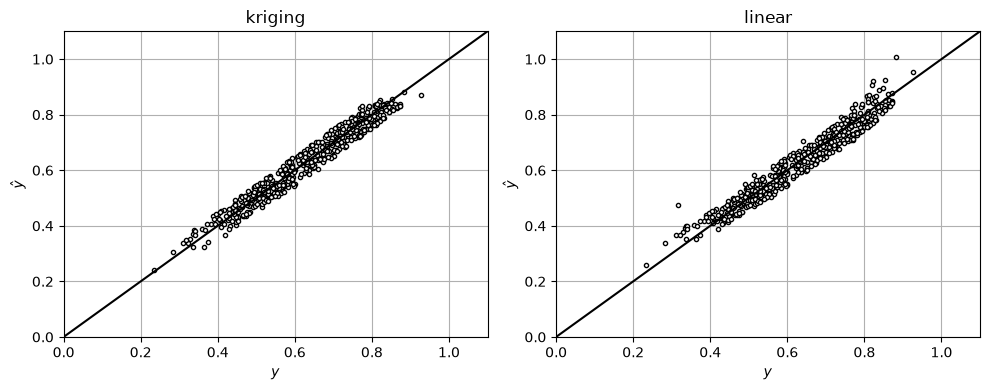

In [3]:
kernel = Matern(length_scale=1, nu=1.5) + WhiteKernel(noise_level=0.01)   # K(gamma) + sigma^2 I
gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True, n_restarts_optimizer=10, random_state=0).fit(X, y)
m_x, sigma_x = gp.predict(X, return_std=True)            # sigma_x includes the noise term
lin = LinearRegression().fit(X, y)
eps_gp, eps_lin = y - m_x, y - lin.predict(X)
print("fitted kernel:", gp.kernel_)

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, pred, title in ((axs[0], m_x, 'kriging'), (axs[1], lin.predict(X), 'linear')):
    ax.plot(y, pred, 'ko', markerfacecolor='w', markersize=3)
    ax.plot([0, 1.1], [0, 1.1], 'k-')
    ax.set_title(title); ax.set_xlabel('$y$'); ax.set_ylabel(r'$\hat{y}$')
    ax.axis([0, 1.1, 0, 1.1]); ax.grid(True)
plt.tight_layout()
plt.show()

Compare the residuals through the empirical cdf of $|\epsilon|$.

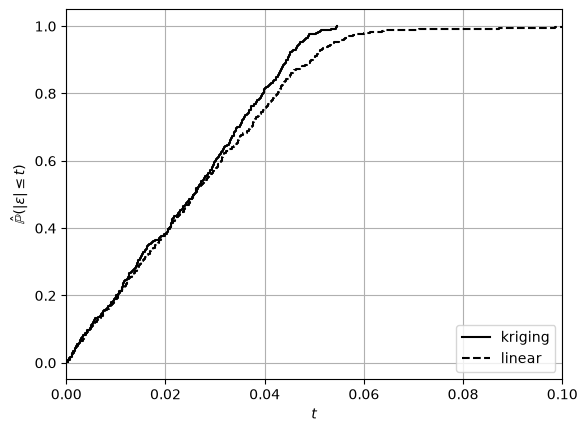

In [4]:
for eps, style, label in ((eps_gp, 'k-', 'kriging'), (eps_lin, 'k--', 'linear')):
    e = np.sort(np.abs(eps))
    plt.step(e, np.arange(1, S + 1) / S, style, where='post', label=label)
plt.xlim(0, 0.1)
plt.xlabel('$t$'); plt.ylabel(r'$\hat{\mathbb{P}}(|\epsilon|\leq t)$')
plt.legend(loc='lower right'); plt.grid(True)
plt.show()

95% confidence intervals $m(x_\omega)\pm 1.96\,\sigma(x_\omega)$ for the first 50 observations.

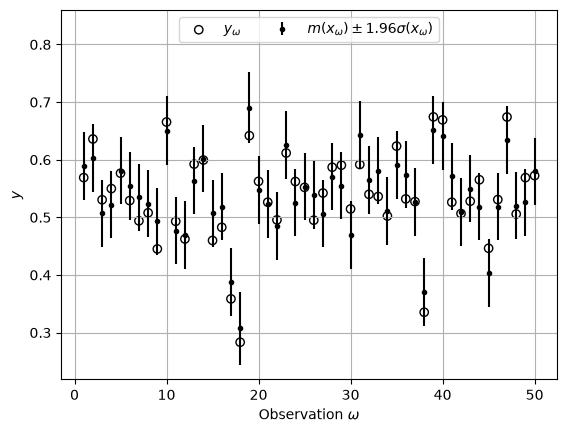

In [5]:
w = np.arange(1, 51)
plt.errorbar(w, m_x[:50], yerr=1.96 * sigma_x[:50], fmt='k.', markersize=6, label=r'$m(x_\omega)\pm1.96\sigma(x_\omega)$')
plt.scatter(w, y[:50], color='black', facecolors='none', label=r'$y_\omega$')
plt.xlabel(r'Observation $\omega$'); plt.ylabel('$y$')
plt.ylim(top=0.86); plt.legend(loc='upper center', ncol=2); plt.grid(True)
plt.show()

**The math, from scratch.** Repeat the prediction with linear algebra for the first 50 observations. The library scales the outputs, $\tilde{\mathbf{y}}=(\mathbf{y}-\bar{y})/s_y$, and $c(x)=1+\sigma^2$ includes the noise term. The noise does not enter $\mathbf{k}(x)$, because the noise of a new measurement is independent of the data.

In [6]:
ell, s2 = gp.kernel_.k1.length_scale, gp.kernel_.k2.noise_level
def k(A, B):
    r = np.sqrt(((A[:, None, :] - B[None, :, :])**2).sum(axis=2))
    return (1 + np.sqrt(3) * r / ell) * np.exp(-np.sqrt(3) * r / ell)

y_t = (y - y.mean()) / y.std()
C = k(X, X) + (s2 + 1e-10) * np.eye(S)                   # 1e-10: numerical jitter of the library
kx = k(X[:50], X)
m_scratch = y.mean() + y.std() * kx @ np.linalg.solve(C, y_t)
v = 1 + s2 - np.sum(kx * np.linalg.solve(C, kx.T).T, axis=1)
print(f"largest difference from scikit-learn: mean {np.abs(m_scratch - m_x[:50]).max():.1e}, "
      f"SD {np.abs(y.std() * np.sqrt(v) - sigma_x[:50]).max():.1e}")
print(f"observations inside the 95% interval: {np.mean(np.abs(y - m_x) <= 1.96 * sigma_x):.1%}")

largest difference from scikit-learn: mean 1.1e-14, SD 4.2e-16
observations inside the 95% interval: 100.0%


**Note:** As in the book, the observed values always lie within the predicted confidence intervals: the GP characterizes its uncertainty consistently.